# Axis 8 — Batch Size vs Cache Contention (Mac / MLX)

**Question.** As more requests are decoded together, more distinct experts are needed at once. Does that destroy the locality that makes an expert cache work?

**Hypothesis (from the team page).** Small batches keep strong locality and high hit rates. As batch size grows, the union of experts needed per step grows faster than the cache, causing thrashing (rapid evict/reload cycles) that can make throughput *worse* than smaller batches despite better compute use — so an optimal batch size exists.

## Method — real batched decoding, no simulation
* B requests are decoded **together**: one forward pass per step for the whole batch (left-padded prompts, mlx-lm `BatchKVCache`).
* 16 short requests written for this axis (math, code, chat, writing), of similar length so padding stays small. Batch B takes the first B in round-robin order, so every batch mixes traffic like a server would.
* For each (B, K), a fresh disk-backed cache of K slots serves the batch.

| Metric | Meaning |
|---|---|
| union per layer per step | distinct experts one layer needs for one decode step of the whole batch (≤ min(64, 8B)) |
| step footprint | Σ over 16 layers of that union = cache lookups per step |
| hit rate | decode phase only (prefill includes padding tokens) |
| reloads / step | misses on experts that were already loaded earlier in the run and got evicted — the thrash rate |
| aggregate throughput | B × steps ÷ decode time |
| per-step latency | p50 / p95 step time — every request in the batch waits for the step |
| exactness | each batched output vs the same request decoded alone |

**Runtime.** Full config ≈ 30–45 min. `MOE_SMOKE=1` takes a few minutes.

In [1]:
import os, sys, time, json, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlx.core as mx

# Shared code: the `moe` package in src/. `pip install -e ".[mac]"` installs it; the path
# line below makes the notebook work without installing.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'moe').is_dir())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from moe import common, mlx_cache as mc, results as rs, figures as fg   # mc is Mac only (MLX)
for m in (common, mc, rs, fg):
    importlib.reload(m)                # pick up edits to src/moe without restarting the kernel

# MOE_SMOKE=1 runs a tiny configuration end to end (used to test the notebook).
SMOKE = os.environ.get('MOE_SMOKE') == '1'
AXIS_DIR = ROOT / 'experiments' / 'axis-8-batch-contention'
RESULTS = (ROOT / 'experiments' / '.cache' / 'smoke' / 'axis-8-batch-contention') if SMOKE else (AXIS_DIR / 'results')
RESULTS.mkdir(parents=True, exist_ok=True)

DEVICE = 'mac'                          # results file: <axis>/results/mac.json
AXIS = 'axis-8-batch-contention'
TABLES = {}                             # every table this run produces, saved at the end

plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
print('SMOKE run' if SMOKE else 'Full run', '| results ->', RESULTS.relative_to(ROOT))
print(mc.system_info())

Full run | results -> experiments/axis-8-batch-contention/results
{'chip': 'Apple M4', 'ram_GB': 17.2, 'macOS': '27.2', 'python': '3.14.8', 'mlx': '0.32.2'}


## Configuration

In [2]:
BATCH_SIZES = [1, 2, 4, 8, 16]
K_VALUES = [256, 512]
MAX_NEW_TOKENS = 32
CHECK_EXACTNESS = True         # decode each request alone once, compare token by token

if SMOKE:
    BATCH_SIZES, K_VALUES, MAX_NEW_TOKENS = [1, 2], [256], 6
print('B:', BATCH_SIZES, '| K:', K_VALUES, '| new tokens:', MAX_NEW_TOKENS)
CONFIG = rs.config_from(globals())   # recorded in the results file

B: [1, 2, 4, 8, 16] | K: [256, 512] | new tokens: 32


## Model and correctness gate

In [3]:
model, tokenizer, index = mc.load_model()
print(index.describe())
print(f'Non-expert weights resident: {mc.non_expert_bytes(model) / 1e9:.2f} GB '
      f'| MLX active memory: {mx.get_active_memory() / 1e9:.2f} GB')
# Measured ONCE, before any expert bank exists: free RAM read later in the run is unreliable.
SAFE_K = mc.max_safe_capacity(index)
print(f'Largest K that fits in the RAM free right now: {SAFE_K} (bank {SAFE_K * index.expert_bytes / 1e9:.1f} GB)')

# Correctness gate: one layer through the K-slot bank vs the stock mlx-lm layer
# (all 64 experts of that layer stacked). Must be bit-identical.
diff = mc.check_layer_exactness(model, index, capacity=64)
assert diff == 0.0, diff
print(f'Layer exactness vs stock mlx-lm: max |diff| = {diff}')

16 layers x 64 experts = 1024 logical experts | 12.58 MB each (F16) | full bank 12.9 GB on disk
Non-expert weights resident: 0.95 GB | MLX active memory: 0.95 GB
Largest K that fits in the RAM free right now: 493 (bank 6.2 GB)


Layer exactness vs stock mlx-lm: max |diff| = 0.0


## Requests

In [4]:
# Short one-line requests of similar length, so left-padding in a batch stays small.
# Four kinds of request; a batch of B takes the first B in round-robin order (mixed traffic).
prompt_file = rs.load_prompts(AXIS_DIR)   # axis-8-batch-contention/prompts.json, shared by every device
PROMPTS = prompt_file['PROMPTS']
reqs = mc.requests(PROMPTS, order='interleave')[:max(BATCH_SIZES)]
toks = [mc.chat_tokens(tokenizer, r['text']) for r in reqs]
print('domains :', [r['domain'][:4] for r in reqs])
print('lengths :', [len(t) for t in toks])

domains : ['math', 'code', 'chat', 'writ', 'math', 'code', 'chat', 'writ', 'math', 'code', 'chat', 'writ', 'math', 'code', 'chat', 'writ']
lengths : [27, 26, 26, 26, 26, 25, 22, 24, 29, 27, 23, 24, 34, 25, 24, 25]


## Reference: each request decoded alone

In [5]:
# Only time K values whose bank fits (SAFE_K was measured at load, before any bank existed).
skipped = [k for k in K_VALUES if k > SAFE_K]
K_VALUES = [k for k in K_VALUES if k <= SAFE_K]
assert K_VALUES, (f'No K fits in free RAM (largest safe K = {SAFE_K}). Close other apps and re-run.')
if skipped:
    print(f'Skipped K={skipped}: the bank would not fit in the RAM free right now (largest safe K = {SAFE_K}).')

singles = None
if CHECK_EXACTNESS:
    cache = mc.ExpertCache(index, min(K_VALUES), 'LRU')   # outputs do not depend on K
    mc.attach_cache(model, cache, [])
    singles = [mc.generate(model, tokenizer, t, MAX_NEW_TOKENS).tokens for t in toks]
    cache.close(); mc.detach_cache(model); mc.free_memory()
    print(f'{len(singles)} single-request references decoded')

Skipped K=[512]: the bank would not fit in the RAM free right now (largest safe K = 493).


16 single-request references decoded


## Sweep

In [6]:
rows, step_rows = [], []
for K in K_VALUES:
    for B in BATCH_SIZES:
        mc.free_memory(); mx.reset_peak_memory()
        cache = mc.ExpertCache(index, K, 'LRU')
        rec = mc.Recorder()
        mc.attach_cache(model, cache, [rec])
        r = mc.generate_batch(model, tokenizer, toks[:B], MAX_NEW_TOKENS,
                              on_step=lambda ph, i: rec.set(phase=ph, step=i))
        s = cache.summary()
        peak = mx.get_peak_memory() / 1e9

        # replay == real (exact), then classify each miss: first load vs reload (thrash)
        acc = mc.events_frame(rec.events)
        hits = mc.replay(rec.events, mc.make_policy('LRU', K))
        assert int(hits.sum()) == s['hits']
        seen, reload = set(), np.zeros(len(acc), bool)
        for i, key in enumerate(zip(acc.layer, acc.eid)):
            if not hits[i] and key in seen:
                reload[i] = True
            seen.add(key)
        dec = (acc.phase == 'decode').to_numpy()
        n_steps = len(r['step_ms'])
        ev = pd.DataFrame(rec.events)
        evd = ev[ev.phase == 'decode']
        union = evd.eids.map(len)

        match = float('nan')
        if singles is not None:
            match = np.mean([np.mean([a == b for a, b in zip(r['tokens'][i], singles[i])]) for i in range(B)])

        step = np.array(r['step_ms'])
        rows.append({
            'K': K, 'B': B, 'ttft_s': r['ttft_s'], 'decode_s': r['decode_s'],
            'agg_tok_s': B * n_steps / r['decode_s'], 'per_req_tok_s': n_steps / r['decode_s'],
            'step_p50_ms': np.median(step), 'step_p95_ms': np.percentile(step, 95),
            'step_cv': step.std() / step.mean(),
            'union_per_layer': union.mean(), 'step_footprint': union.sum() / n_steps,
            'decode_hit_rate': hits[dec].mean(), 'reloads_per_step': reload[dec].sum() / n_steps,
            'loads_per_step': (~hits[dec]).sum() / n_steps,
            'io_share': s['io_ms'] / 1000 / (r['ttft_s'] + r['decode_s']),
            'peak_GB': peak, 'token_match': match,
        })
        cache.close(); mc.detach_cache(model)
        x = rows[-1]
        print(f'K={K} B={B:2d}: {x["agg_tok_s"]:5.2f} tok/s total ({x["per_req_tok_s"]:.2f}/req) | '
              f'step p50 {x["step_p50_ms"]:6.0f} ms | union/layer {x["union_per_layer"]:4.1f} | '
              f'footprint {x["step_footprint"]:5.0f} | hit {x["decode_hit_rate"]:5.1%} | '
              f'reloads/step {x["reloads_per_step"]:5.1f} | match {x["token_match"]:.0%}')

res = pd.DataFrame(rows)
TABLES['runs'] = res
res.style.format(precision=2)

K=256 B= 1:  3.87 tok/s total (3.87/req) | step p50    244 ms | union/layer  8.0 | footprint   128 | hit 50.9% | reloads/step  60.2 | match 100%


K=256 B= 2:  4.48 tok/s total (2.24/req) | step p50    443 ms | union/layer 14.2 | footprint   228 | hit 50.6% | reloads/step 111.2 | match 100%


K=256 B= 4:  2.47 tok/s total (0.62/req) | step p50   1547 ms | union/layer 26.0 | footprint   416 | hit  0.0% | reloads/step 415.2 | match 100%


K=256 B= 8:  3.10 tok/s total (0.39/req) | step p50   2482 ms | union/layer 38.4 | footprint   615 | hit  0.0% | reloads/step 614.2 | match 100%


K=256 B=16:  3.99 tok/s total (0.25/req) | step p50   4148 ms | union/layer 49.1 | footprint   786 | hit  0.0% | reloads/step 785.3 | match 95%


,K,B,ttft_s,decode_s,agg_tok_s,per_req_tok_s,step_p50_ms,step_p95_ms,step_cv,union_per_layer,step_footprint,decode_hit_rate,reloads_per_step,loads_per_step,io_share,peak_GB,token_match
0,256,1,3.61,8.02,3.87,3.87,244.29,398.08,0.28,8.00,128.00,0.51,60.16,62.84,0.81,4.22,1.00
1,256,2,3.96,13.82,4.48,2.24,442.64,616.03,0.22,14.24,227.87,0.51,111.19,112.58,0.84,4.26,1.00
2,256,4,4.48,50.19,2.47,0.62,1546.53,2224.79,0.15,26.01,416.13,0.00,415.23,416.13,0.89,4.34,1.00
3,256,8,4.73,80.03,3.10,0.39,2481.58,3655.68,0.20,38.42,614.74,0.00,614.16,614.74,0.89,4.50,1.00
4,256,16,5.22,124.45,3.99,0.25,4147.73,4892.70,0.14,49.10,785.65,0.00,785.29,785.65,0.92,4.84,0.95


## Plots

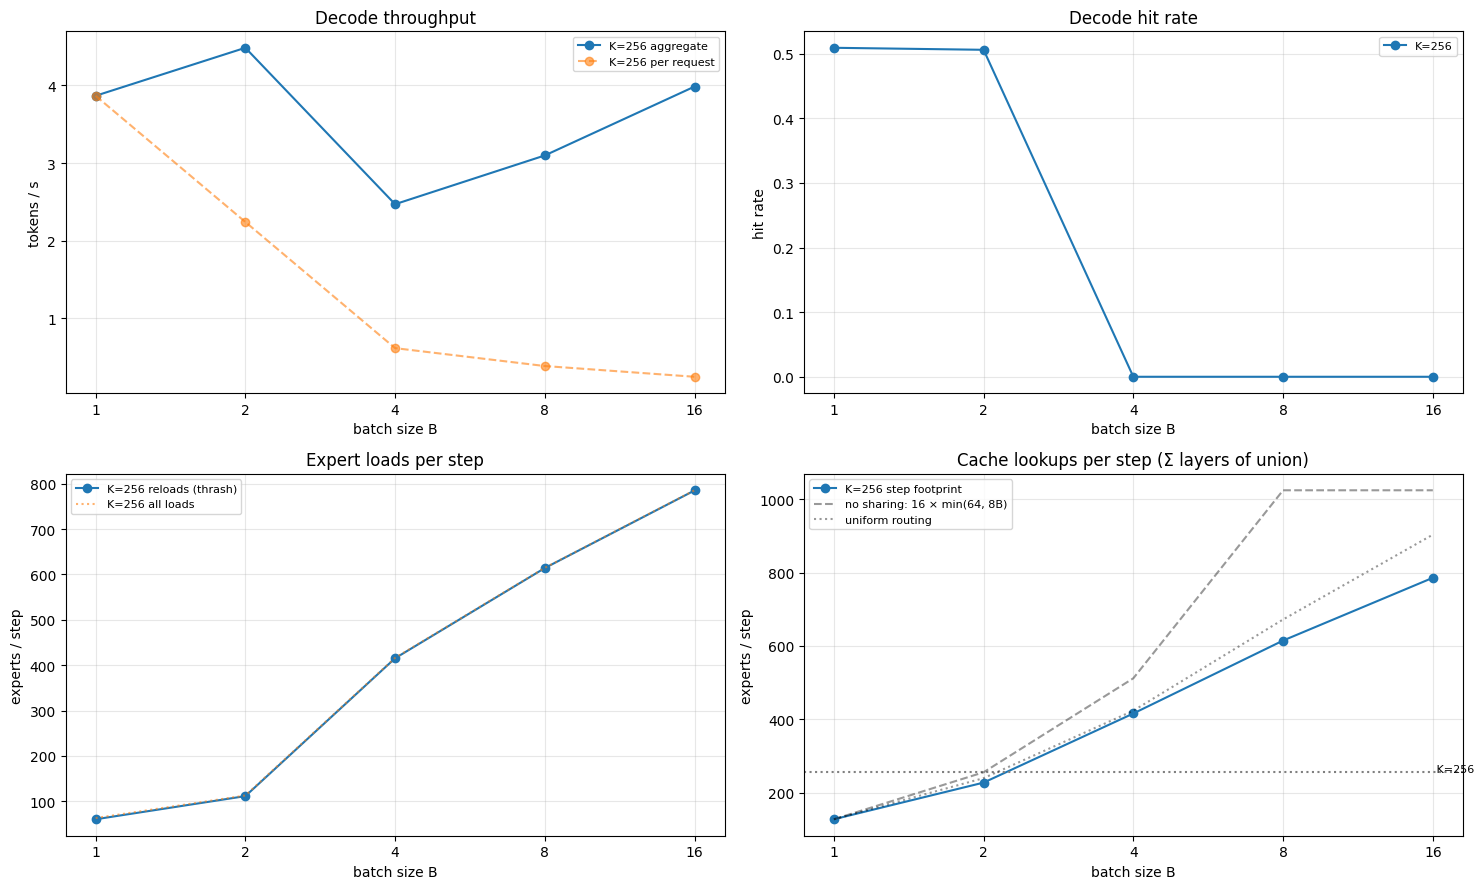

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for K, d in res.groupby('K'):
    axes[0, 0].plot(d.B, d.agg_tok_s, '-o', label=f'K={K} aggregate')
    axes[0, 0].plot(d.B, d.per_req_tok_s, '--o', alpha=0.6, label=f'K={K} per request')
    axes[0, 1].plot(d.B, d.decode_hit_rate, '-o', label=f'K={K}')
    axes[1, 0].plot(d.B, d.reloads_per_step, '-o', label=f'K={K} reloads (thrash)')
    axes[1, 0].plot(d.B, d.loads_per_step, ':', alpha=0.6, label=f'K={K} all loads')
    axes[1, 1].plot(d.B, d.step_footprint, '-o', label=f'K={K} step footprint')
    axes[1, 1].axhline(K, ls=':', color='grey'); axes[1, 1].text(max(BATCH_SIZES), K, f' K={K}', fontsize=8)
B = np.array(BATCH_SIZES)
axes[1, 1].plot(B, 16 * np.minimum(64, 8 * B), 'k--', alpha=0.4, label='no sharing: 16 × min(64, 8B)')
axes[1, 1].plot(B, 16 * 64 * (1 - (1 - 8 / 64) ** B), 'k:', alpha=0.4, label='uniform routing')
for ax, t, yl in zip(axes.flat, ['Decode throughput', 'Decode hit rate', 'Expert loads per step',
                                 'Cache lookups per step (Σ layers of union)'],
                     ['tokens / s', 'hit rate', 'experts / step', 'experts / step']):
    ax.set_xscale('log', base=2); ax.set_xticks(BATCH_SIZES); ax.set_xticklabels(BATCH_SIZES)
    ax.set_xlabel('batch size B'); ax.set_title(t); ax.set_ylabel(yl); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Hypothesis check (descriptive)

In [8]:
for K, d in res.groupby('K'):
    d = d.set_index('B')
    b_best = int(d.agg_tok_s.idxmax())
    grow = d.union_per_layer / d.union_per_layer.iloc[0]
    print(f'K={K}: best aggregate throughput at B={b_best} ({d.agg_tok_s.max():.2f} tok/s); '
          f'B=1 gives {d.agg_tok_s.iloc[0]:.2f}. Union per layer grows {grow.iloc[-1]:.1f}x from B=1 to '
          f'B={d.index[-1]} while tokens per step grow {d.index[-1]}x. Hit rate {d.decode_hit_rate.iloc[0]:.0%} '
          f'-> {d.decode_hit_rate.iloc[-1]:.0%}; reloads/step {d.reloads_per_step.iloc[0]:.0f} -> '
          f'{d.reloads_per_step.iloc[-1]:.0f}.')
    worse = [b for b in d.index[1:] if d.agg_tok_s[b] < d.agg_tok_s.loc[:b].iloc[:-1].max()]
    print(f'   Batch sizes where aggregate throughput falls below a smaller batch: {worse or "none"}')
if singles is not None:
    print(f'\nBatched outputs match single-request outputs on {res.token_match.mean():.1%} of tokens '
          '(rare flips come from float rounding in batched kernels).')

K=256: best aggregate throughput at B=2 (4.48 tok/s); B=1 gives 3.87. Union per layer grows 6.1x from B=1 to B=16 while tokens per step grow 16x. Hit rate 51% -> 0%; reloads/step 60 -> 785.
   Batch sizes where aggregate throughput falls below a smaller batch: [4, 8, 16]

Batched outputs match single-request outputs on 99.0% of tokens (rare flips come from float rounding in batched kernels).


## Save results
Every table above goes into **one file for this device**: `results/mac.json`, with the configuration, prompts and machine it ran on.
The Windows notebooks write `windows-igpu.json` / `windows-dgpu.json` next to it in the same format (see `experiments/README.md`).

In [ ]:
CONFIG['SAFE_K'] = globals().get('SAFE_K')
path = rs.save(RESULTS, AXIS, DEVICE, TABLES, config=CONFIG, prompts=rs.load_prompts(AXIS_DIR),
               system=mc.system_info())
print('Saved', path.relative_to(ROOT), '| tables:', {k: len(v) for k, v in TABLES.items()})

## Cross-device figures
The report figures, drawn from every device's results file in this folder (colour = device). Only shown here;
`python -m moe.figures` writes them to `figures/` once all devices have results.

In [ ]:
figs = fg.make(AXIS, RESULTS)